In [3]:
"""
Name: Jacob Sharon
Date: 11-09-2026
Class: CSC635

This file implements the Feed Forward Neural Network for our groups class project.

Updates:
11-09-2026:
    - Imports, rough outline as TODO cells, set up MLP class for main experiment.
11-18-2026:
    - Began preprocessing: reading csv, verifying dtypes, verifying ranges.
    - Identified columns from initial read for drop based on clinical utility.
11-23-2026:
    - Completed pre-processing: feature selection, missing-value handling, and categorical encoding.
    - Added stratified splitting, standardization, and tensor conversion.
    - Verified input shapes and types; applied positive-class weighting.
    - Updated Markdown documentation.
11-24-2026:
    - Added discharge exclusions and diagnosis grouping with one-hot encoding (credit to Sudarshan).
    - Set up experiment runner for best configuration of hidden layers, learning rate, and dropout rates.
    - Selected the best validation F1 model, plotted training curves, confusion matrix, and AUC.
    - Saved results in csv and png files. 
    - Stubbed analysis section for 11-25-2026
11-25-2026:
    - TODO: Analysis 
        - Encounters from the same patient may appear in different sets - to be addressed in analysis.
    - TODO: Possibly remove all drugs except insulin and metformin and see if classification improves. 
"""

'\nName: Jacob Sharon\nDate: 11-09-2026\nClass: CSC635\n\nThis file implements the Feed Forward Neural Network for our groups class project.\n\nUpdates:\n11-09-2026:\n    - Imports, rough outline as TODO cells, set up MLP class for main experiment.\n11-18-2026:\n    - Began preprocessing: reading csv, verifying dtypes, verifying ranges.\n    - Identified columns from initial read for drop based on clinical utility.\n11-23-2026:\n    - Completed pre-processing: feature selection, missing-value handling, and categorical encoding.\n    - Added stratified splitting, standardization, and tensor conversion.\n    - Verified input shapes and types; applied positive-class weighting.\n    - Updated Markdown documentation.\n11-24-2026:\n    - Added discharge exclusions and diagnosis grouping with one-hot encoding (credit to Sudarshan).\n    - Set up experiment runner for best configuration of hidden layers, learning rate, and dropout rates.\n    - Selected the best validation F1 model, plotted tr

In [4]:
# Imports

# Data and Preprocessing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay

# Pytorch 
import torch
import torch.nn as nn
import torch.nn.init as init
from torch.utils.data import TensorDataset, DataLoader

# Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

In [5]:
# Load the dataset

diabetic_data = pd.read_csv("../Data/diabetic_data.csv")

diabetic_data

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO


# Preprocessing: Discovery and Feature Selection

I am a Medical Laboratory Scientist and perform high-complexity testing on patients of this demographic. My work is primarily in clinical chemistry, and my previous experience includes supervisory/managerial roles involving billing and ordering using the coding system described in this dataset. I am basing decisions about feature selection on my professional knowledge and understanding of the problem. 

Definitions are based on the [UCI dataset documentation](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008).

## Missing Data and Discharge Exclusions

Replaced ? and invalid gender entries with NaN. Excluded encounters with discharge disposition IDs 11, 19, 20, and 21 before calculating missing counts and percentages.

In [7]:
# Preprocessing: Identify columns with missing data and quantify missing data.

# Replace all '?' with NaN.
diabetic_data = diabetic_data.replace('?', np.nan)

# Treat invalid gender entries as missing.
diabetic_data['gender'] = diabetic_data['gender'].replace('Unknown/Invalid', np.nan)

# Exclude encounters with expired discharge disposition codes.
diabetic_data = diabetic_data[~diabetic_data['discharge_disposition_id'].isin([11,19,20,21])]

# Show missing counts and percentages after the discharge exclusions.
missing_data = pd.DataFrame({
    'missing_count': diabetic_data.isna().sum(),
    'missing_percent': (diabetic_data.isna().mean() * 100).round(2)
})

print(missing_data.to_string())

                          missing_count  missing_percent
encounter_id                          0             0.00
patient_nbr                           0             0.00
race                               2239             2.24
gender                                3             0.00
age                                   0             0.00
weight                            96958            96.85
admission_type_id                     0             0.00
discharge_disposition_id              0             0.00
admission_source_id                   0             0.00
time_in_hospital                      0             0.00
payer_code                        39591            39.55
medical_specialty                 49129            49.07
num_lab_procedures                    0             0.00
num_procedures                        0             0.00
num_medications                       0             0.00
number_outpatient                     0             0.00
number_emergency               

## Medication Use

Medication status indicates whether a drug was prescribed and whether the dosage changed.

- No: drug was not prescribed.
- Steady: dosage did not change.
- Up: dosage increased.
- Down: dosage decreased.

Counted Steady, Up, and Down as medication use. Calculated encounter counts, encounter percentages, and unique patient counts for each drug.

In [9]:
# Preprocessing: Count medication use to help determine which features to retain.

drug_cols = [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide',
    'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
    'miglitol', 'troglitazone', 'tolazamide', 'examide',
    'citoglipton', 'insulin', 'glyburide-metformin',
    'glipizide-metformin', 'glimepiride-pioglitazone',
    'metformin-rosiglitazone', 'metformin-pioglitazone'
]

# Steady, Up, and Down indicate the medication was prescribed.
drug_used = diabetic_data[drug_cols].isin(['Steady', 'Up', 'Down'])

drug_counts = pd.DataFrame({
    'encounters': drug_used.sum(),
    'encounter_percent': (drug_used.mean() * 100).round(2),
    'patients': drug_used.groupby(diabetic_data['patient_nbr']).max().sum()
})

print(drug_counts.sort_values('encounters', ascending=False).to_string())

                          encounters  encounter_percent  patients
insulin                        53434              53.37     38890
metformin                      19898              19.88     16415
glipizide                      12605              12.59      9935
glyburide                      10567              10.55      8500
pioglitazone                    7281               7.27      5902
rosiglitazone                   6329               6.32      5156
glimepiride                     5147               5.14      4153
repaglinide                     1527               1.53      1169
glyburide-metformin              698               0.70       560
nateglinide                      695               0.69       572
acarbose                         307               0.31       235
chlorpropamide                    85               0.08        75
tolazamide                        39               0.04        33
miglitol                          38               0.04        24
tolbutamid

## Feature Selection and Target

- weight, payer_code, and medical_specialty: dropped due to limited recorded data.
- max_glu_serum and A1Cresult: test-result ranges or test not measured; dropped because most encounters have no measured result.
- encounter_id and patient_nbr: record identifiers; excluded from model inputs.
- diag_2 and diag_3: secondary diagnoses; dropped to focus on the primary diagnosis.
- Medications prescribed in fewer than 100 encounters: dropped due to limited examples, leaving 11 medications.

Converted readmission within 30 days to 1 and later or no recorded readmission to 0. Dropped 21 columns, leaving 28 inputs before one-hot encoding and one target.

In [11]:
# Preprocessing: Drop columns that are not needed or have too much missing data.

# Drop medications prescribed in fewer than 100 encounters.
drugs_to_drop = [
    'chlorpropamide', 'tolazamide', 'miglitol', 'tolbutamide',
    'glipizide-metformin', 'troglitazone', 'metformin-rosiglitazone',
    'acetohexamide', 'glimepiride-pioglitazone', 'metformin-pioglitazone',
    'examide', 'citoglipton'
]

diabetic_data.drop(
    columns=[
        'encounter_id', 'patient_nbr', 'weight', 'payer_code',
        'medical_specialty', 'max_glu_serum', 'A1Cresult', 'diag_2', 'diag_3'
    ] + drugs_to_drop,
    inplace=True
)

# Convert readmission within 30 days to a binary target.
diabetic_data['readmitted'] = (diabetic_data['readmitted'] == '<30').astype(int)
print(diabetic_data['readmitted'].value_counts())

readmitted
0    88757
1    11357
Name: count, dtype: int64


## Primary Diagnosis

diag_1: primary diagnosis recorded as an ICD-9 code. Grouped it into nine disease categories, with a separate Missing category, to reduce the number of inputs created by one-hot encoding.

- Adapted the diagnosis_group function from [Sudarshan Tiwari's logistic regression notebook](https://github.com/jacobsharon/CSC635-Group-Project/blob/main/Logistic_Regression/logistic_regression.ipynb).
- Added missing-value handling and used the integer portion of decimal codes to determine the group. V and E codes are assigned to Other.
- Retained only diag_1.

In [13]:
# Preprocessing: Group primary diagnoses before categorical encoding.

def diagnosis_group(code):
    """
    Assign a primary ICD-9 diagnosis to a general disease category.

    Parameters
    ----------
    code : str or float
        Diagnosis code from diag_1, which may contain a decimal or be missing.

    Returns
    -------
    str
        Disease category, Other, or Missing for missing or excluded entries.

    Notes
    -----
    Adapted from Sudarshan Tiwari's diagnosis_group function in
    Logistic_Regression/logistic_regression.ipynb in this project.
    Added missing-value handling and used the integer portion of numeric codes
    before checking the disease ranges. V and E codes are assigned to Other.
    """
    if pd.isna(code):
        return 'Missing'
    code = str(code).strip().upper()
    if code.startswith(('V', 'E')):
        return 'Other'
    try:
        value = float(code)
    except ValueError:
        return 'Missing'
    if not np.isfinite(value) or not 0 <= value < 1000:
        return 'Missing'

    # Use the integer portion so decimal codes stay within their disease group.
    value = int(value)
    if 390 <= value <= 459 or value == 785:
        return 'Circulatory'
    if 460 <= value <= 519 or value == 786:
        return 'Respiratory'
    if 520 <= value <= 579 or value == 787:
        return 'Digestive'
    if value == 250:
        return 'Diabetes'
    if 800 <= value <= 999:
        return 'Injury'
    if 710 <= value <= 739:
        return 'Musculoskeletal'
    if 580 <= value <= 629 or value == 788:
        return 'Genitourinary'
    if 140 <= value <= 239:
        return 'Neoplasms'
    return 'Other'


diabetic_data['diag_1'] = diabetic_data['diag_1'].apply(diagnosis_group)
print(diabetic_data['diag_1'].value_counts().to_string())

diag_1
Circulatory        29881
Other              17887
Respiratory        14074
Digestive           9380
Diabetes            8693
Injury              6881
Genitourinary       5054
Musculoskeletal     4944
Neoplasms           3299
Missing               21


## Categorical Missing Values

- Converted admission type, discharge disposition, and admission source IDs to strings so they are handled as categories.
- Identified all text-based categorical columns and replaced their missing entries with a separate Missing category.
- No encounters were dropped in this step.

In [15]:
# Preprocessing: Treat admission and discharge IDs as categorical features.

coded_cols = [
    'admission_type_id', 
    'discharge_disposition_id', 
    'admission_source_id'
]

# String values allow get_dummies to recognize these IDs as categories.
diabetic_data[coded_cols] = diabetic_data[coded_cols].astype('string')

categorical_cols = diabetic_data.select_dtypes(
    include=['object', 'string']
).columns.tolist()

# Replace missing categorical values with a separate category.
diabetic_data[categorical_cols] = diabetic_data[categorical_cols].fillna('Missing')

## Categorical Encoding

- Identified numerical measurements before encoding.
- One-hot encoded race, gender, age intervals, admission and discharge categories, diagnosis groups, medication status, change, and diabetesMed.

In [17]:
# Preprocessing: Identify numerical measurements before one-hot encoding.

numeric_cols = diabetic_data.select_dtypes(
    include=['number']
).columns.drop('readmitted').tolist()

# One-hot encode categories, including the primary diagnosis groups.
diabetic_data = pd.get_dummies(
    diabetic_data,
    columns=categorical_cols,
    dtype='float32'
)

print("Dataset shape after encoding:", diabetic_data.shape)
print("Input features:", diabetic_data.shape[1] - 1)

Dataset shape after encoding: (100114, 134)
Input features: 133


## Train, Validation, and Test Split

- Separated the inputs from the readmission target.
- Used stratified random splits by encounter: 60% for training, 20% for validation, and 20% for testing.
- Encounters from the same patient may appear in different sets - to be addressed in analysis.
- Validation was used to select hyperparameters and the best epoch; testing evaluates the selected model.

In [19]:
# Preprocessing: Separate features and target.

X = diabetic_data.drop(columns=['readmitted'])
y = diabetic_data['readmitted']

# Reserve 20% for final testing.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Use 25% of the remaining data for validation (20% overall).
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

# Check class counts and percentages in all three sets.
class_counts = pd.DataFrame({
    'training_count': y_train.value_counts(),
    'validation_count': y_val.value_counts(),
    'testing_count': y_test.value_counts(),
    'training_percent': y_train.value_counts(normalize=True).mul(100),
    'validation_percent': y_val.value_counts(normalize=True).mul(100),
    'testing_percent': y_test.value_counts(normalize=True).mul(100)
})

print(class_counts.sort_index().round(2).to_string())

            training_count  validation_count  testing_count  training_percent  validation_percent  testing_percent
readmitted                                                                                                        
0                    53254             17751          17752             88.66               88.65            88.66
1                     6814              2272           2271             11.34               11.35            11.34


## Standardization and Loading to Tensors

- Fitted StandardScaler on numerical measurements in the training set and applied it to validation and testing.
- Left one-hot indicators unscaled.
- Converted all inputs to float32, and loaded into tensors.
- Targets are float32 tensors with one column to match the MLP output for BCEWithLogitsLoss.

In [21]:
# Preprocessing: Standardize numerical features using training data and load into tensors.

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

scaler = StandardScaler()

X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_val[numeric_cols] = scaler.transform(X_val[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

# Convert all input features to float32 for PyTorch.
X_train = X_train.astype('float32')
X_val = X_val.astype('float32')
X_test = X_test.astype('float32')

# Preprocessing: Convert inputs and targets to PyTorch tensors.

X_train_tensor = torch.tensor(X_train.to_numpy(), dtype=torch.float32)
X_val_tensor = torch.tensor(X_val.to_numpy(), dtype=torch.float32)
X_test_tensor = torch.tensor(X_test.to_numpy(), dtype=torch.float32)

# BCEWithLogitsLoss requires float targets matching the output shape.
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.float32).reshape(-1, 1)

print("X_train_tensor:", X_train_tensor.shape, X_train_tensor.dtype)
print("X_val_tensor:", X_val_tensor.shape, X_val_tensor.dtype)
print("X_test_tensor:", X_test_tensor.shape, X_test_tensor.dtype)
print("y_train_tensor:", y_train_tensor.shape, y_train_tensor.dtype)
print("y_val_tensor:", y_val_tensor.shape, y_val_tensor.dtype)
print("y_test_tensor:", y_test_tensor.shape, y_test_tensor.dtype)

X_train_tensor: torch.Size([60068, 133]) torch.float32
X_val_tensor: torch.Size([20023, 133]) torch.float32
X_test_tensor: torch.Size([20023, 133]) torch.float32
y_train_tensor: torch.Size([60068, 1]) torch.float32
y_val_tensor: torch.Size([20023, 1]) torch.float32
y_test_tensor: torch.Size([20023, 1]) torch.float32


In [22]:
# Neural Network Implementation

class MLP(nn.Module):
    """
    A fully connected feedforward neural network (Multi-Layer Perceptron)
    used for binary classification of early readmission of diabetic patients
    within 30 days of discharge.

    Each hidden layer uses ReLU activation and configurable dropout.
    Batch normalization is applied after hidden linear layers except the first.
    Kaiming uniform initialization is applied to all Linear weights, and
    biases are initialized to zero. The output is an unbounded logit for
    BCEWithLogitsLoss.

    Parameters
    ----------
    input_size : int
        Number of input features.
    hidden_sizes : list of int
        Number of neurons in each hidden layer, such as [28] or [28, 14].
    output_size : int
        Number of output neurons. For binary classification, this is 1.
    dropout : float, optional
        Probability of dropping a hidden activation. Defaults to 0.0.

    Attributes
    ----------
    network : nn.Sequential
        Hidden layers and output layer in forward order.
    """

    def __init__(self, input_size, hidden_sizes, output_size, dropout=0.0):
        super().__init__()
        layers = []

        # First hidden layer (no batch normalization here).
        layers.append(nn.Linear(input_size, hidden_sizes[0]))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(p=dropout))

        # Remaining hidden layers.
        for i in range(len(hidden_sizes) - 1):
            layers.append(nn.Linear(hidden_sizes[i], hidden_sizes[i + 1]))
            layers.append(nn.BatchNorm1d(hidden_sizes[i + 1]))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(p=dropout))

        # Output layer produces logits.
        layers.append(nn.Linear(hidden_sizes[-1], output_size))
        self.network = nn.Sequential(*layers)
        self._init_weights()

    def _init_weights(self):
        """
        Initialize Linear weights with Kaiming uniform and zero biases.

        Returns
        -------
        None
            Updates the weights and biases of the Linear layers in place.
        """
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                init.kaiming_uniform_(layer.weight, nonlinearity='relu')
                if layer.bias is not None:
                    init.zeros_(layer.bias)

    def forward(self, x):
        """
        Perform a forward pass through the network.

        Parameters
        ----------
        x : torch.Tensor
            Input tensor of shape (batch_size, input_size).

        Returns
        -------
        torch.Tensor
            Raw logits of shape (batch_size, output_size). The output size is
            1 for this experiment. Pass logits directly to BCEWithLogitsLoss
            during training and apply sigmoid when calculating probabilities.
        """
        return self.network(x)

## Loss Function and Class Imbalance

- Used BCEWithLogitsLoss with positive class weighting.
- Calculated the weight as negative training cases divided by positive training cases.
- Validation and testing cases are excluded from this calculation.
- The MLP returns logits, sigmoid is applied when calculating probabilities and metrics.
- Sigmoid threshold is 0.5

In [24]:
# Loss function: Account for class imbalance using training targets only.

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

# Weight the positive-class loss by the negative-to-positive training ratio.
ratio = negative_count / positive_count

# Keep the weight on the same device and dtype as the target tensors.
pos_weight = torch.tensor(
    [ratio], dtype=y_train_tensor.dtype, device=y_train_tensor.device
)

# Pass raw MLP logits directly to BCEWithLogitsLoss.
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print("Negative training cases:", negative_count)
print("Positive training cases:", positive_count)
print(f"Positive class weight: {ratio:.4f}")
print("Loss weight tensor:", criterion.pos_weight)
print(criterion)

Negative training cases: 53254
Positive training cases: 6814
Positive class weight: 7.8154
Loss weight tensor: tensor([7.8154])
BCEWithLogitsLoss()


## Experiment Settings

Hyperparameters Tested - 18 Configurations:
- Hidden Layers: [28] and [28, 14]
- Learning Rates: [0.001, 0.0001, 0.0005]
- Dropout probabilities [0.00, 0.10, 0.20]

Constants: 
- Optimizer: AdamW Kept
- Seed: 42
- Batch Size: 256
- Weight Decay 0.01
- Training-ratio class weight: 7.81 (see calculation above)
- Threshold: 0.50
- Epochs: 100, early stopping after 10 epochs without improved validation F1.

In [26]:
# Experiments: Define the hyperparameters to test and the fixed settings.

from itertools import product
from sklearn.metrics import f1_score

# Vary the hidden layers, learning rate, and dropout across 18 runs.
hidden_options = [[28], [28, 14]]
learning_rates = [0.001, 0.0001, 0.0005]
dropout_options = [0.0, 0.10, 0.20]

batch_size = 256
max_epochs = 100
patience = 10
weight_decay = 0.01
classification_threshold = 0.50
random_seed = 42
output_size = 1

train_data = TensorDataset(X_train_tensor, y_train_tensor)
parameter_grid = list(product(hidden_options, learning_rates, dropout_options))

print("Input features:", X_train_tensor.shape[1])
print("Hidden layers:", hidden_options)
print("Learning rates:", learning_rates)
print("Dropout probabilities:", dropout_options)
print("Optimizer: AdamW")
print("Positive class weight:", round(float(ratio), 4))
print("Classification threshold:", classification_threshold)
print("Maximum epochs:", max_epochs)
print("Early stopping patience:", patience)
print("Configurations:", len(parameter_grid))

Input features: 133
Hidden layers: [[28], [28, 14]]
Learning rates: [0.001, 0.0001, 0.0005]
Dropout probabilities: [0.0, 0.1, 0.2]
Optimizer: AdamW
Positive class weight: 7.8154
Classification threshold: 0.5
Maximum epochs: 100
Early stopping patience: 10
Configurations: 18


## Training Runner

- Started each run with a fresh MLP and the same seed and batch order.
- AdamW updates the weights and biases using gradients from the weighted BCE loss.
- Used validation F1 to save the best checkpoint and stop after 10 epochs without improvement, up to 100 epochs.
- Restored that checkpoint before reporting results. Validation AUC breaks ties between configurations.
- Recorded training, validation, and testing loss each epoch. Training loss includes dropout when enabled; validation and testing use evaluation mode. Testing loss is recorded for plotting only.

In [28]:
# Experiments: Calculate model performance at the fixed threshold.

@torch.no_grad()
def evaluate_model(model, inputs, targets):
    """
    Calculate weighted loss and classification metrics without updating weights.

    Parameters
    ----------
    model : MLP
        Network to evaluate using its current weights.
    inputs : torch.Tensor
        Float32 input tensor of shape (number_of_encounters, input_size).
    targets : torch.Tensor
        Float32 binary targets of shape (number_of_encounters, 1).

    Returns
    -------
    dict
        Weighted BCE loss, accuracy, precision, recall, F1, and ROC AUC.
        Also includes the predicted probabilities and binary predictions.

    Notes
    -----
    Uses the previously defined criterion and classification_threshold.
    Evaluation mode disables dropout and uses stored batch normalization
    statistics. Sigmoid probabilities are used for AUC; thresholded
    predictions are used for the other classification metrics.
    """
    model.eval()
    logits = model(inputs)
    probabilities = torch.sigmoid(logits).numpy().ravel()
    predictions = (probabilities >= classification_threshold).astype(int)
    actual = targets.numpy().ravel()

    return {
        'loss': criterion(logits, targets).item(),
        'accuracy': accuracy_score(actual, predictions),
        'precision': precision_score(actual, predictions, zero_division=0),
        'recall': recall_score(actual, predictions, zero_division=0),
        'f1': f1_score(actual, predictions, zero_division=0),
        'auc': roc_auc_score(actual, probabilities),
        'probabilities': probabilities,
        'predictions': predictions
    }


# Experiments: Train one configuration using AdamW.
def train_model(hidden_sizes, learning_rate, dropout):
    """
    Train one MLP configuration and restore its best validation F1 checkpoint.

    Parameters
    ----------
    hidden_sizes : list of int
        Number of neurons in each hidden layer.
    learning_rate : float
        Learning rate used by the AdamW optimizer.
    dropout : float
        Probability of dropping a hidden activation during training.

    Returns
    -------
    dict
        Restored model, tested hyperparameters, best epoch, epochs run,
        validation metrics, and training, validation, and testing loss histories.

    Notes
    -----
    Uses the prepared tensors, weighted criterion, and fixed experiment settings.
    Resets the random seed and batch order for each run. Training minimizes
    weighted BCE loss. Checkpoint selection and early stopping use validation
    F1, with a patience of 10 epochs in this experiment. Testing loss is
    recorded for plotting and is not used to select the model.
    """
    torch.manual_seed(random_seed)
    model = MLP(
        X_train_tensor.shape[1], hidden_sizes, output_size, dropout=dropout
    )
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=learning_rate, weight_decay=weight_decay
    )

    # Use the same shuffled batch order for every configuration.
    generator = torch.Generator().manual_seed(random_seed)
    train_loader = DataLoader(
        train_data, batch_size=batch_size, shuffle=True, generator=generator
    )

    training_loss = []
    validation_loss = []
    testing_loss = []
    best_f1 = -1
    epochs_without_improvement = 0

    for epoch in range(max_epochs):
        model.train()
        total_loss = 0

        for inputs, targets in train_loader:
            # Clear previous gradients and calculate the weighted batch loss.
            optimizer.zero_grad()
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Calculate gradients and update the model parameters.
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * inputs.shape[0]

        # Record mean training loss and evaluate the validation set without dropout.
        validation = evaluate_model(model, X_val_tensor, y_val_tensor)
        training_loss.append(total_loss / len(train_data))
        validation_loss.append(validation['loss'])

        # Test loss is recorded for plotting only, without updating parameters.
        with torch.no_grad():
            test_loss = criterion(model(X_test_tensor), y_test_tensor).item()
        testing_loss.append(test_loss)

        # Early stopping and checkpoint selection use validation F1 only.
        if validation['f1'] > best_f1:
            best_f1 = validation['f1']
            best_epoch = epoch + 1
            epochs_without_improvement = 0
            best_state = {
                name: value.detach().clone()
                for name, value in model.state_dict().items()
            }
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    # Restore weights, biases, and batch normalization state from the best epoch.
    model.load_state_dict(best_state)
    validation = evaluate_model(model, X_val_tensor, y_val_tensor)

    return {
        'model': model,
        'hidden_sizes': hidden_sizes.copy(),
        'learning_rate': learning_rate,
        'optimizer': 'AdamW',
        'dropout': dropout,
        'best_epoch': best_epoch,
        'epochs_run': len(training_loss),
        'validation': validation,
        'training_loss': training_loss,
        'validation_loss': validation_loss,
        'testing_loss': testing_loss
    }

## Hyperparameter Tuning

- Ran all 18 combinations and printed training and validation metrics at each runs best checkpoint. 
- Selected the highest validation F1, using validation AUC to break ties. 
- Retains only the best model and its loss history for final evaluation.

In [30]:
# Experiments: Tune both architectures and retain the best validation F1 model.

rows = []
best_run = None

for number, (layers, learning_rate, dropout) in enumerate(parameter_grid, start=1):
    run = train_model(layers, learning_rate, dropout)
    training = evaluate_model(run['model'], X_train_tensor, y_train_tensor)
    validation = run['validation']

    rows.append({
        'hidden_layers': str(layers),
        'learning_rate': learning_rate,
        'dropout': dropout,
        'best_epoch': run['best_epoch'],
        'epochs_run': run['epochs_run'],
        'accuracy': validation['accuracy'],
        'precision': validation['precision'],
        'recall': validation['recall'],
        'f1': validation['f1'],
        'auc': validation['auc']
    })

    # Print training and validation metrics at each run's best checkpoint.
    network = [X_train_tensor.shape[1]] + layers + [output_size]
    print(f"Run {number}/{len(parameter_grid)}: network={network}, AdamW, "
          f"lr={learning_rate}, dropout={dropout}", flush=True)
    print(f"Best epoch={run['best_epoch']}, epochs run={run['epochs_run']}")
    for name, results in [('Training', training), ('Validation', validation)]:
        print(f"{name}: loss={results['loss']:.4f}, accuracy={results['accuracy']:.4f}, "
              f"precision={results['precision']:.4f}, recall={results['recall']:.4f}, "
              f"F1={results['f1']:.4f}, AUC={results['auc']:.4f}", flush=True)
    print()

    # Select by validation F1 and use validation AUC only to break a tie.
    if best_run is None or (validation['f1'], validation['auc']) > (
        best_run['validation']['f1'], best_run['validation']['auc']
    ):
        best_run = run

model = best_run['model']
experiment_results = pd.DataFrame(rows).sort_values(
    ['f1', 'auc'], ascending=[False, False]
).reset_index(drop=True)

print("Results ranked by validation F1, then AUC:")
print(experiment_results.round(4).to_string(index=False))
print("Selected network:", [X_train_tensor.shape[1]] + best_run['hidden_sizes'] + [output_size])
print("Selected learning rate:", best_run['learning_rate'])
print("Selected dropout:", best_run['dropout'])
print("Selected epoch:", best_run['best_epoch'])
print(f"Best validation F1: {best_run['validation']['f1']:.4f}")
print(f"Selected model validation AUC: {best_run['validation']['auc']:.4f}")

Run 1/18: network=[133, 28, 1], AdamW, lr=0.001, dropout=0.0
Best epoch=6, epochs run=16
Training: loss=1.1388, accuracy=0.6939, precision=0.1931, recall=0.5343, F1=0.2837, AUC=0.6800
Validation: loss=1.1454, accuracy=0.6978, precision=0.1974, recall=0.5423, F1=0.2894, AUC=0.6767

Run 2/18: network=[133, 28, 1], AdamW, lr=0.001, dropout=0.1
Best epoch=6, epochs run=16
Training: loss=1.1375, accuracy=0.6641, precision=0.1860, recall=0.5807, F1=0.2817, AUC=0.6799
Validation: loss=1.1449, accuracy=0.6686, precision=0.1881, recall=0.5792, F1=0.2840, AUC=0.6761

Run 3/18: network=[133, 28, 1], AdamW, lr=0.001, dropout=0.2
Best epoch=11, epochs run=21
Training: loss=1.1275, accuracy=0.6519, precision=0.1851, recall=0.6082, F1=0.2838, AUC=0.6893
Validation: loss=1.1425, accuracy=0.6537, precision=0.1851, recall=0.6030, F1=0.2832, AUC=0.6791

Run 4/18: network=[133, 28, 1], AdamW, lr=0.0001, dropout=0.0
Best epoch=67, epochs run=77
Training: loss=1.1325, accuracy=0.6663, precision=0.1878, reca

## Final Model Results and Plots

- Evaluated the restored best model.
- Printed performance metrics. 
- Plotting of Loss Curves, AUC, and Confusion Matrix

Selected network: [133, 28, 1]
Optimizer: AdamW
Learning rate: 0.0005
Dropout: 0.0
Best epoch: 23
Epochs run: 33
Classification threshold: 0.5
           validation  testing
loss           1.1427   1.1550
accuracy       0.6993   0.6945
precision      0.1978   0.1894
recall         0.5401   0.5165
f1             0.2896   0.2772
auc            0.6808   0.6666


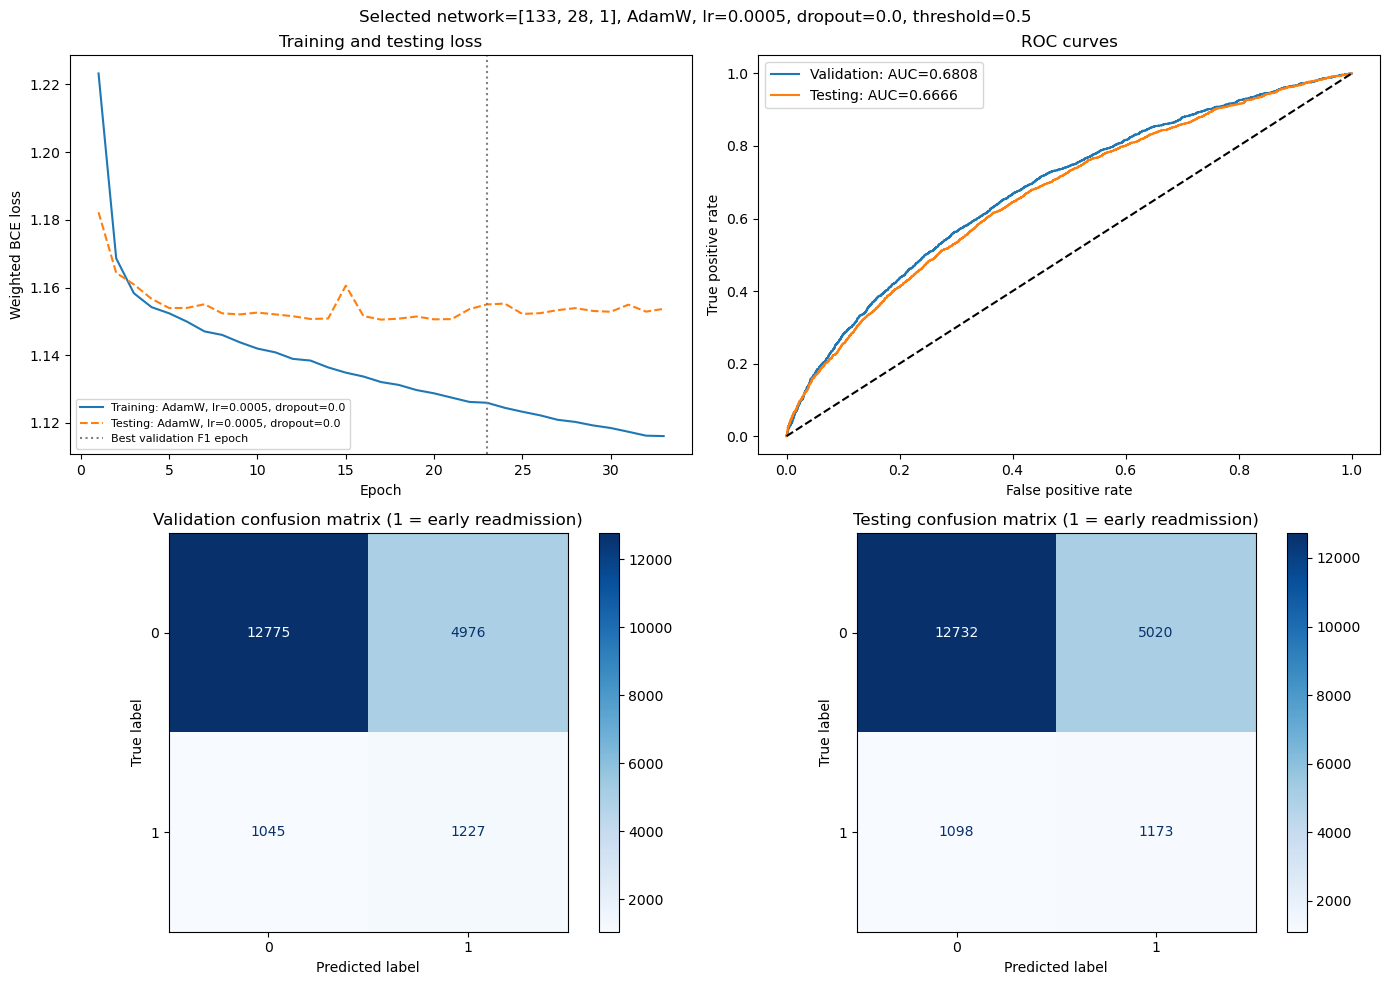

In [32]:
# Experiments: Evaluate and plot the best validation F1 model.

validation_results = evaluate_model(model, X_val_tensor, y_val_tensor)
test_results = evaluate_model(model, X_test_tensor, y_test_tensor)

metric_names = ['loss', 'accuracy', 'precision', 'recall', 'f1', 'auc']
final_metrics = pd.DataFrame({
    'validation': {name: validation_results[name] for name in metric_names},
    'testing': {name: test_results[name] for name in metric_names}
})
network = [X_train_tensor.shape[1]] + best_run['hidden_sizes'] + [output_size]
label = (f"AdamW, lr={best_run['learning_rate']}, "
         f"dropout={best_run['dropout']}")

print("Selected network:", network)
print("Optimizer: AdamW")
print("Learning rate:", best_run['learning_rate'])
print("Dropout:", best_run['dropout'])
print("Best epoch:", best_run['best_epoch'])
print("Epochs run:", best_run['epochs_run'])
print("Classification threshold:", classification_threshold)
print(final_metrics.round(4).to_string())

# Compare the selected run's loss across epochs and mark its best checkpoint.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
epoch_numbers = range(1, best_run['epochs_run'] + 1)
axes[0, 0].plot(epoch_numbers, best_run['training_loss'], label=f"Training: {label}")
axes[0, 0].plot(epoch_numbers, best_run['testing_loss'], linestyle='--',
                label=f"Testing: {label}")
axes[0, 0].axvline(best_run['best_epoch'], color='gray', linestyle=':',
                   label='Best validation F1 epoch')
axes[0, 0].set(xlabel='Epoch', ylabel='Weighted BCE loss',
                title='Training and testing loss')
axes[0, 0].legend(fontsize=8)

# ROC curves use probabilities across thresholds, rather than binary predictions.
for actual, results, split in [
    (y_val, validation_results, 'Validation'),
    (y_test, test_results, 'Testing')
]:
    fpr, tpr, thresholds = roc_curve(actual, results['probabilities'])
    axes[0, 1].plot(fpr, tpr, label=f"{split}: AUC={results['auc']:.4f}")
axes[0, 1].plot([0, 1], [0, 1], 'k--')
axes[0, 1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves')
axes[0, 1].legend()

# Rows show actual classes; columns show predicted classes at threshold 0.50.
for axis, actual, results, split in zip(
    axes[1], [y_val, y_test], [validation_results, test_results], ['Validation', 'Testing']
):
    ConfusionMatrixDisplay.from_predictions(
        actual, results['predictions'], labels=[0, 1], ax=axis, cmap='Blues'
    )
    axis.set_title(f'{split} confusion matrix (1 = early readmission)')

fig.suptitle(f"Selected network={network}, {label}, threshold={classification_threshold}")
plt.tight_layout()
plt.show()

In [33]:
# Save experiment results, final metrics, loss history, and figures.

experiment_results.to_csv('Results/hyperparameter_results.csv', index=False)
final_metrics.to_csv('Results/final_model_metrics.csv', index_label='metric')

loss_history = pd.DataFrame({
    'epoch': range(1, best_run['epochs_run'] + 1),
    'training_loss': best_run['training_loss'],
    'validation_loss': best_run['validation_loss'],
    'testing_loss': best_run['testing_loss']
})
loss_history.to_csv('Results/loss_history.csv', index=False)

fig.savefig('Results/final_model_plots.png', dpi=300, bbox_inches='tight')

print("Saved hyperparameter_results.csv, final_model_metrics.csv,")
print("loss_history.csv, and final_model_plots.png to Results.")

Saved hyperparameter_results.csv, final_model_metrics.csv,
loss_history.csv, and final_model_plots.png to Results.


# Analysis: 

## Results
## Limitations
## Future Directions
## Conclusion